<img src="https://www.th-koeln.de/img/logo.svg" style="float:right;" width="200">

# 1st exercise: <font color="#C70039">Work with standard deviations for anomaly detection</font>
* Course: AML
* Lecturer: <a href="https://www.gernotheisenberg.de/">Gernot Heisenberg</a>
* Author of notebook: <b>Yara Dinesh Kumar</b>
* Matriculation number: <b>11701170</b>
* Date:   16.11.2026

<img src="https://upload.wikimedia.org/wikipedia/commons/8/8c/Standard_deviation_diagram.svg" style="float: center;" width="450">

---------------------------------
**GENERAL NOTE 1**:
Please make sure you are reading the entire notebook, since it contains a lot of information on your tasks (e.g. regarding the set of certain parameters or a specific computational trick), and the written mark downs as well as comments contain a lot of information on how things work together as a whole.

**GENERAL NOTE 2**:
* Please, when commenting source code, just use English language only.
* When describing an observation please use English language, too
* This applies to all exercises throughout this course.  

---------------------

### <font color="ce33ff">DESCRIPTION</font>:
This notebook allows you for getting into standard deviations as a common technique to detect anomalies when the data is normally distributed.

-------------------------------------------------------------------------------------------------------------

### <font color="FFC300">TASKS</font>:
The tasks that you need to work on within this notebook are always indicated below as bullet points.
If a task is more challenging and consists of several steps, this is indicated as well.
Make sure you have worked down the task list and commented your doings.
This should be done by using markdown.<br>
<font color=red>Make sure you don't forget to specify your name and your matriculation number in the notebook.</font>

**YOUR TASKS in this exercise are as follows**:
1. import the notebook to Google Colab or use your local machine.
2. make sure you specified your name and your matriculation number in the header below my name and date.
    * set the date too and remove mine.
3. read the entire notebook carefully
    * add comments wherever you feel it necessary for better understanding
    * run the notebook for the first time.
    * understand the output
4. go and find three different data sets on the web
    * kaggle.com might be a good source (they also offer an API for data download)
    * make sure two of the three data sets are normally distributed
    * download one data set that is not normally distributed
5. visualize the data
6. compute the anomalies
7. visualize the anomalies
8. does the 0,3% rule apply?
9. what are differences between the normally distributed and the non-normally distributed data sets with respect to the outlier detection?
10. which statement can be made and which cannot?
-----------------------------------------------------------------------------------

In [7]:
# Google Colab setup: make repository files available under the expected relative paths.
import os
import subprocess
import sys

if "google.colab" in sys.modules:
    repository = "/content/AML"
    if not os.path.isdir(repository):
        subprocess.run(["git", "clone", "--depth", "1", "https://github.com/gheisenberg/AML.git", repository], check=True)
    os.chdir(repository)

In [8]:
import numpy as np
import matplotlib.pyplot as plt

rng = np.random.default_rng(1)

In [9]:
def find_anomalies(values, z_threshold=3.0):
    # Convert the input to a one-dimensional numeric array.
    values = np.asarray(values, dtype=float).ravel()
    if values.size == 0:
        return np.array([], dtype=float)

    mean = values.mean()
    standard_deviation = values.std()
    lower_limit = mean - z_threshold * standard_deviation
    upper_limit = mean + z_threshold * standard_deviation

    print(f"lower limit = {lower_limit:.8f}")
    print(f"upper limit = {upper_limit:.8f}")

    anomaly_mask = (values < lower_limit) | (values > upper_limit)
    return values[anomaly_mask]

In [10]:
# Generate 50,000 synthetic data points following a normal (Gaussian) distribution
# with mean = 20.0 and standard deviation = 20.0
data = rng.normal(loc=20.0, scale=20.0, size=50_000)


In [11]:
# Detect anomalies lying outside +/- 3 standard deviations from the mean
anomalies = find_anomalies(data)

lower limit = -39.90059055
upper limit = 79.56133068


## Result
The detected observations lie outside the interval of three standard deviations around the sample mean.

For an exactly normal distribution, about 99.73% of observations lie inside this interval and about 0.27% lie outside it. This probabilistic interpretation depends on the normality assumption; the rule is not generally valid for skewed, heavy-tailed, or multimodal data.

In [12]:
print(f"Detected {anomalies.size} anomalies ({anomalies.size / data.size:.3%} of the sample).")
print(anomalies)

Detected 157 anomalies (0.314% of the sample).
[ 82.00084598 -41.60355518 -50.97609942  95.03269935  83.72172404
  79.98127129  81.56366494 -43.44335183  83.42093185  94.35280914
  86.01435064  87.34351352  83.56984536 -43.38001006  82.83592963
 -44.9639731   98.63555761  84.17701563  80.67648988  84.96603376
 -50.12028395  88.17999973 -41.6258273   88.79596806 -42.90332063
  81.49154017 -41.42707812  87.00841243 -49.38275455  89.59537682
 -53.28499202 -56.75724285 -47.28200425 -41.79280137  81.76060279
  98.67109755  86.84069414  80.19483029  82.11159463  84.75917972
  81.3304144   91.59834046 -40.43904982  84.9498064  -42.93356822
  82.90079712  81.27523437  89.05261684  90.30548657 -51.6209516
 -48.74748696  81.04462774  82.1493208  -43.32186356  79.57889449
  92.48900341  81.8804014   85.07578131  86.43808125  86.38556949
  82.23463869  81.83187509 -48.08668702  92.03037682  96.16158265
 -57.68310144 -47.0364295  -43.5203909  -46.52273788 -45.33751851
  79.56260629  87.45464669 -52

## Exercise Solutions: Real-World Datasets Analysis
### Task 4: Loading Three Datasets via Kaggle API (2 Normal, 1 Non-Normal)
Three real-world datasets from Kaggle:
1. **Normal Dataset 1:** Human Heights (`Height(Inches)`) from the SOCR Height & Weight dataset.
2. **Normal Dataset 2:** Student Weekly Study Hours (`weekly_self_study_hours`) from the Student Performance dataset.
3. **Non-Normal Dataset:** Median Household Income (`median_income`) from the California Housing dataset, which is right-skewed.


In [13]:
import glob
import os
import kagglehub
import pandas as pd
from google.colab import userdata

# Load Kaggle API token securely from Colab Secrets
os.environ["KAGGLE_API_TOKEN"] = userdata.get("KAGGLE_API_TOKEN")

# 1. Normal Dataset 1: Human Heights
path_1 = kagglehub.dataset_download("burnoutminer/heights-and-weights-dataset")
df_1 = pd.read_csv(glob.glob(os.path.join(path_1, "*.csv"))[0])
data_normal_1 = df_1["Height(Inches)"].dropna().to_numpy()

# 2. Normal Dataset 2: Student Weekly Self-Study Hours
path_2 = kagglehub.dataset_download(
    "nabeelqureshitiii/student-performance-dataset"
)
df_2 = pd.read_csv(glob.glob(os.path.join(path_2, "*.csv"))[0])
data_normal_2 = df_2["weekly_self_study_hours"].dropna().to_numpy()

# 3. Non-Normal Dataset: California Median Income (right-skewed)
path_3 = kagglehub.dataset_download("camnugent/california-housing-prices")
df_3 = pd.read_csv(glob.glob(os.path.join(path_3, "*.csv"))[0])
data_non_normal = df_3["median_income"].dropna().to_numpy()

print(
    f"Loaded samples -> Heights: {data_normal_1.size}, Study Hours:"
    f" {data_normal_2.size}, Income: {data_non_normal.size}"
)

Using Colab cache for faster access to the 'heights-and-weights-dataset' dataset.
Using Colab cache for faster access to the 'student-performance-dataset' dataset.
Using Colab cache for faster access to the 'california-housing-prices' dataset.
Loaded samples -> Heights: 25000, Study Hours: 1000000, Income: 20640


### Task 5: Visualizing the Data Distributions
Plot histograms to check the shape of each dataset before running anomaly detection.

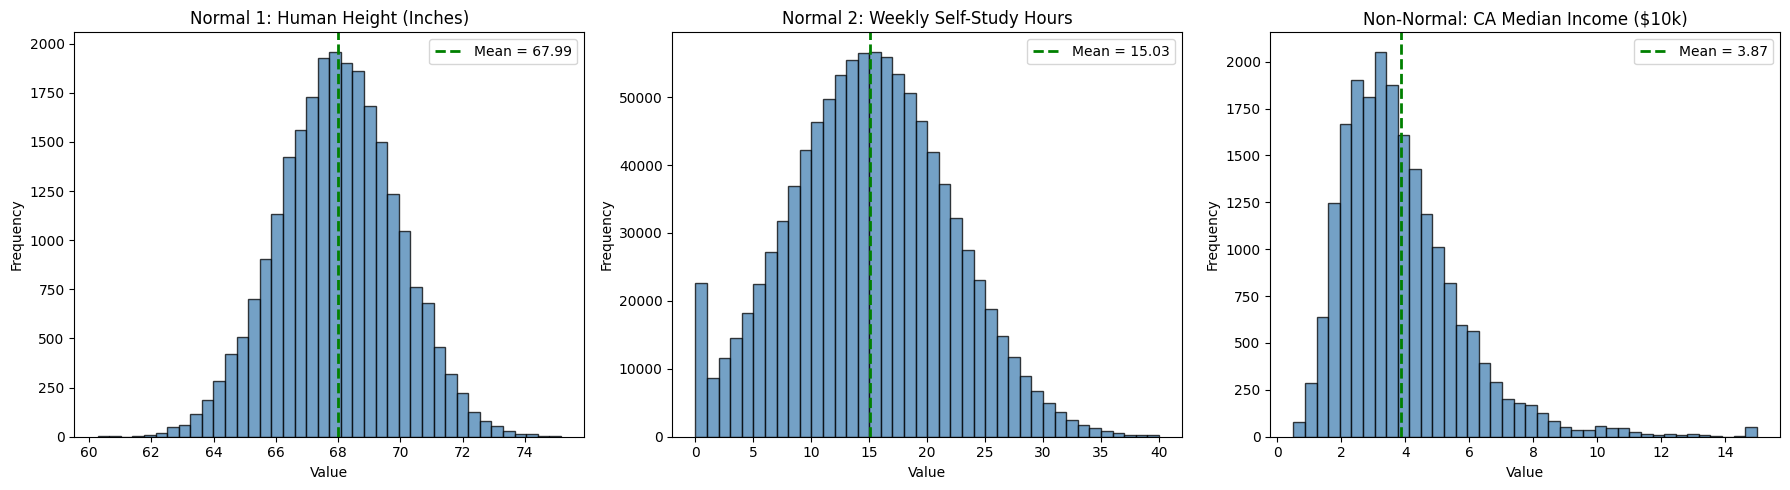

In [14]:
import matplotlib.pyplot as plt
import numpy as np

datasets = {
    "Normal 1: Human Height (Inches)": data_normal_1,
    "Normal 2: Weekly Self-Study Hours": data_normal_2,
    "Non-Normal: CA Median Income ($10k)": data_non_normal,
}

fig, axes = plt.subplots(1, 3, figsize=(18, 5))

for ax, (name, values) in zip(axes, datasets.items()):
    # Plot histogram to inspect whether the data forms a symmetric bell curve
    ax.hist(values, bins=40, color="steelblue", edgecolor="black", alpha=0.75)
    ax.axvline(
        values.mean(),
        color="green",
        linestyle="--",
        linewidth=2,
        label=f"Mean = {values.mean():.2f}",
    )
    ax.set_title(name)
    ax.set_xlabel("Value")
    ax.set_ylabel("Frequency")
    ax.legend()

plt.tight_layout()
plt.show()

### Tasks 6 & 7: Computing and Visualizing Anomalies
Applying `find_anomalies()` function (`z_threshold = 3.0`) to each dataset and plot the detected outliers in red.

--- Normal 1: Human Height (Inches) ---
lower limit = 62.28819139
upper limit = 73.69803581
Detected 51 anomalies out of 25000 samples (0.204%)

--- Normal 2: Weekly Self-Study Hours ---
lower limit = -5.66915581
upper limit = 35.72740961
Detected 1503 anomalies out of 1000000 samples (0.150%)

--- Non-Normal: CA Median Income ($10k) ---
lower limit = -1.82865608
upper limit = 9.56999809
Detected 345 anomalies out of 20640 samples (1.672%)



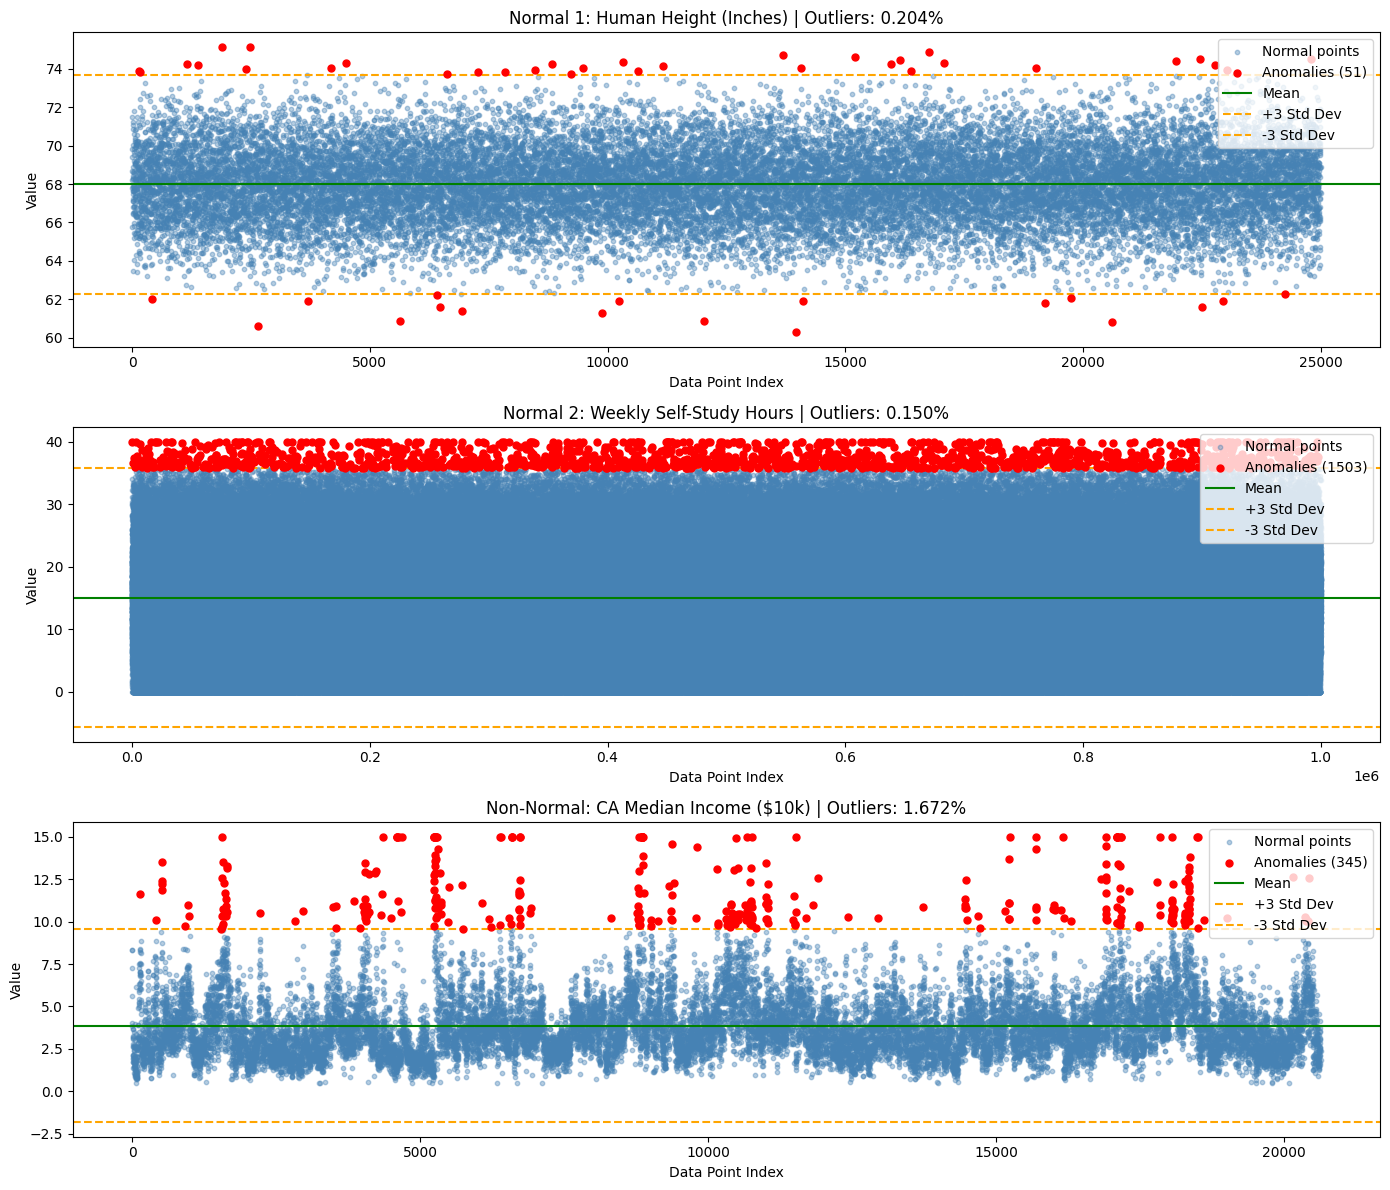

In [15]:
fig, axes = plt.subplots(3, 1, figsize=(14, 12))

for ax, (name, values) in zip(axes, datasets.items()):
    print(f"--- {name} ---")
    # Task 6: Compute anomalies using the existing 3-sigma function
    anomalies = find_anomalies(values, z_threshold=3.0)
    percentage = (anomalies.size / values.size) * 100
    print(
        f"Detected {anomalies.size} anomalies out of {values.size} samples"
        f" ({percentage:.3f}%)\n"
    )

    # Calculate thresholds again for plotting lines
    mean = values.mean()
    std = values.std()
    lower_limit = mean - 3.0 * std
    upper_limit = mean + 3.0 * std

    indices = np.arange(values.size)
    is_anomaly = (values < lower_limit) | (values > upper_limit)

    # Task 7: Plot normal points in blue and anomalies in red
    ax.scatter(
        indices[~is_anomaly],
        values[~is_anomaly],
        color="steelblue",
        alpha=0.4,
        s=10,
        label="Normal points",
    )
    ax.scatter(
        indices[is_anomaly],
        values[is_anomaly],
        color="red",
        s=25,
        zorder=5,
        label=f"Anomalies ({anomalies.size})",
    )
    ax.axhline(mean, color="green", linestyle="-", linewidth=1.5, label="Mean")
    ax.axhline(
        upper_limit,
        color="orange",
        linestyle="--",
        linewidth=1.5,
        label="+3 Std Dev",
    )
    ax.axhline(
        lower_limit,
        color="orange",
        linestyle="--",
        linewidth=1.5,
        label="-3 Std Dev",
    )
    ax.set_title(f"{name} | Outliers: {percentage:.3f}%")
    ax.set_xlabel("Data Point Index")
    ax.set_ylabel("Value")
    ax.legend(loc="upper right")

plt.tight_layout()
plt.show()

### Tasks 8, 9 & 10: Analysis and Conclusions

#### 8. Does the 0.3% rule apply?
* **Normal Dataset 1 : Human Height (`51 / 25,000` anomalies = `0.204%`):** Yes, it applies closely. With a symmetric bell curve centered at `67.99` inches and bounds `[62.29, 73.70]`, `0.204%` of observations fall outside $\pm 3\sigma$ (very close to the theoretical `0.27%` / `~0.3%`)[cite: 6, 7].
* **Normal Dataset 2 : Weekly Self-Study Hours (`1,503 / 1,000,000` anomalies = `0.150%`):** Only half of the `0.3%` rule applies (`0.150%` $\approx \frac{0.30\%}{2}$)[cite: 7]. Because study hours cannot be negative, the data is clipped at `0.0` (visible as the spike at `0` in the histogram)[cite: 6], while the lower threshold is `-5.67`[cite: 7]. Consequently, `0` lower-tail anomalies exist, and only the upper tail (`> 35.73` hours) contributes `0.150%`[cite: 7, 8].
* **Non-Normal Dataset : CA Median Income (`345 / 20,640` anomalies = `1.672%`):** No, the `0.3%` rule completely fails[cite: 7]. Because the income distribution is heavily right-skewed (`mean = 3.87`), `1.672%` of the dataset falls above `+3σ` (`9.57`)—more than **5.5 times** the expected `0.3%` rate—while `0%` falls below `-3σ` (`-1.83`)[cite: 6, 7, 8].

#### 9. What are the differences between the normally distributed and non-normally distributed datasets with respect to outlier detection?
* **Two-Sided vs. One-Sided Detection:** In Dataset 1 (Human Height), anomalies appear symmetrically on **both** the upper tail (`> 73.70`) and lower tail (`< 62.29`)[cite: 7]. In Dataset 3 (CA Median Income), the lower bound (`-1.83`) falls below zero—which is impossible for income—so **all `345` anomalies** are detected exclusively on the high end[cite: 7, 8].
* **Distortion of Mean and Standard Deviation:** In the skewed income dataset, high-income values pull the sample mean upward (`3.87`) and inflate the standard deviation, shifting the $\pm 3\sigma$ interval away from the dense bulk of the data (`2.0–4.5`)[cite: 6, 8].

#### 10. Which statements can be made and which cannot?
* **Statements that CAN be made:**
  * A flagged point lies mathematically more than $3$ standard deviations away from the sample mean ($\lvert z \rvert > 3$).
  * When the data is confirmed to follow an unclipped normal distribution (as in Human Height), a flagged point is statistically rare (occurring roughly `0.2%–0.3%` of the time)[cite: 7].
* **Statements that CANNOT be made:**
  * We **cannot** conclude that a statistical outlier is automatically an error, corrupted sensor reading, or fraud.For example, households earning above `$95,700` (`9.57` in `$10k` units) in California are valid real-world observations, not data mistakes[cite: 7, 8].
  * We **cannot** assume the `0.3%` rule holds without first inspecting the data's distribution for skewness or boundary clipping (as proven by Datasets 2 and 3)[cite: 6, 7, 8].